<a href="https://colab.research.google.com/github/Shreenisha-S30/mini-projects-on-ML/blob/main/day2_diabetes_randomforest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, precision_score, recall_score
import seaborn as sns

In [ ]:
dia = pd.read_excel("/content/diabetesxl.xlsx")
dia.head()

,preg,plas,pres,skin,insu,mass,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,tested_positive
1,1,85,66,29,0,26.6,0.351,31,tested_negative
2,8,183,64,0,0,23.3,0.672,32,tested_positive
3,1,89,66,23,94,28.1,0.167,21,tested_negative
4,0,137,40,35,168,43.1,2.288,33,tested_positive


In [ ]:
dia.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   preg    768 non-null    int64  
 1   plas    768 non-null    int64  
 2   pres    768 non-null    int64  
 3   skin    768 non-null    int64  
 4   insu    768 non-null    int64  
 5   mass    768 non-null    float64
 6   pedi    768 non-null    float64
 7   age     768 non-null    int64  
 8   class   768 non-null    object 
dtypes: float64(2), int64(6), object(1)
memory usage: 54.1+ KB


In [ ]:
dia.isnull().sum()

,0
preg,0
plas,0
pres,0
skin,0
insu,0
mass,0
pedi,0
age,0
class,0


In [ ]:
X = dia[['age','mass','insu','plas']] #independent
Y = dia['class'] #dependent
print(X.shape, Y.shape)

(768, 4) (768,)


In [ ]:
x_train,x_test,y_train,y_test = train_test_split(
    X,Y,test_size= 0.20, random_state=42
)

In [ ]:
print("Records for training:", len(x_train))
print("Records for testing:", len(x_test))

Records for training: 614
Records for testing: 154


In [ ]:
logr = RandomForestClassifier(n_estimators=100,random_state=42)
logr.fit(x_train,y_train)

RandomForestClassifier(random_state=42)

In [ ]:
#test
y_predict = logr.predict(x_test)
result = pd.DataFrame(
    {
        "Actual" : y_test,
        "Prediction_by_model" : y_predict
    }
)
result.head(10)

,Actual,Prediction_by_model
668,tested_negative,tested_positive
324,tested_negative,tested_positive
624,tested_negative,tested_negative
690,tested_negative,tested_negative
473,tested_negative,tested_positive
204,tested_negative,tested_positive
97,tested_negative,tested_negative
336,tested_negative,tested_positive
568,tested_negative,tested_negative
148,tested_negative,tested_positive


In [ ]:
#predict
age = int(input("Enter the age:"))
mass = int(input("Enter the mass:"))
insulin = int(input("Enter the insulin level:"))
plasma = int(input("Enter the plasma level:"))
pred = logr.predict([[age,mass,insulin,plasma]])

print("prediction of diabete:",pred)

Enter the age:40
Enter the mass:30
Enter the insulin level:199
Enter the plasma level:350
prediction of diabete: ['tested_positive']


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [ ]:
if pred == "tested_negative":
  print("You are not diabete. you can eat sweets.")
else:
  print("you are diabete. so eat less sweet.")

you are diabete. so eat less sweet.


In [ ]:
print("Accuracy:", accuracy_score(y_test,y_predict))
print("Precision:", precision_score(y_test, y_predict, pos_label="tested_positive"))
print("Recall:", recall_score(y_test,y_predict,pos_label="tested_positive"))
print("F1 score:",f1_score(y_test,y_predict,pos_label="tested_positive")) #less than 0.6 means we have to reject the model
print("Confusion Matrix:\n", confusion_matrix(y_test,y_predict))

Accuracy: 0.7272727272727273
Precision: 0.6
Recall: 0.7090909090909091
F1 score: 0.65
Confusion Matrix:
 [[73 26]
 [16 39]]


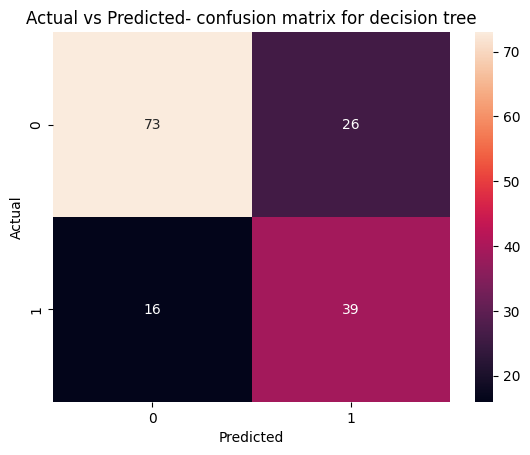

In [ ]:
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test, y_predict)
sns.heatmap(cm, annot=True)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Actual vs Predicted- confusion matrix for decision tree")
plt.show()